Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [1]:
import os
import re
import html
import copy
from time import time
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from gensim.models import KeyedVectors
import gensim.downloader as api

# Para que la descarga funcione con el proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords

try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords', quiet=True)

# Semillas
SEED = 3
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Carga y exploración de los datos

El archivo `movie.csv` tiene 40.000 reseñas con dos columnas: `text` y `label` (0 = negativa, 1 = positiva). No trae el rating, por lo que solo se usa la etiqueta. Las clases están balanceadas (20.019 negativas y 19.981 positivas), no hay nulos y hay 277 reseñas duplicadas.

In [2]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    40000 non-null  str  
 1   label   40000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 50.6 MB


In [3]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [4]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

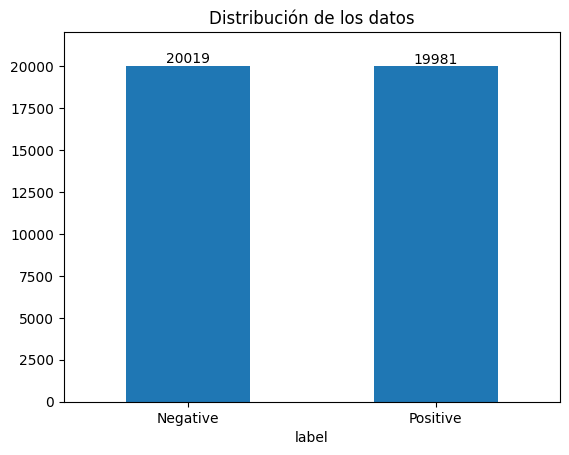

In [5]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # deja espacio arriba para que no se corte el número

In [6]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


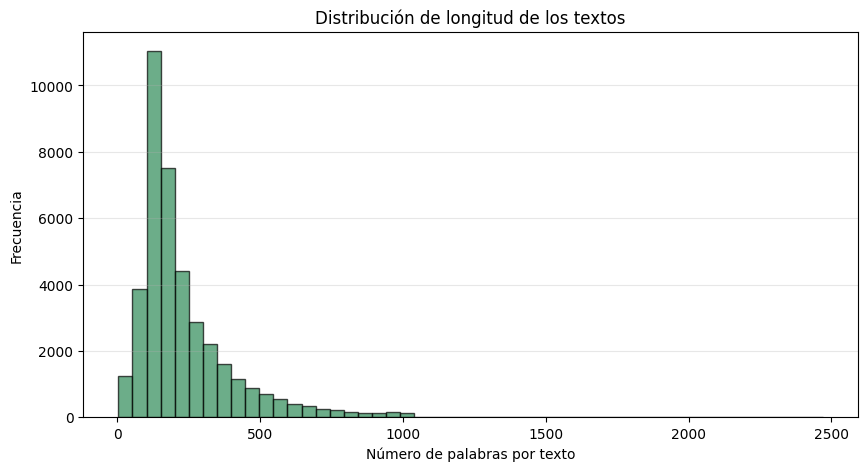

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [7]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

### 3. Separación de los datos

Primero se eliminan los duplicados para que una misma reseña no quede en train y en test (quedan 39.723). Después se divide en 70 % train, 15 % validación y 15 % prueba, estratificado por la etiqueta.

In [8]:
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros sin duplicados: {len(GHI)}")

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(len(train_GHI), len(val_GHI), len(test_GHI))

Registros sin duplicados: 39723
27806 5958 5959


### 4. Limpieza y tokenización

En la limpieza se quitan las etiquetas HTML (`<br />`), las URLs y todo lo que no sea letra, y se pasa a minúscula. Las negaciones contraídas se separan (*didn't* → *did not*) y las otras contracciones (*'s*, *'re*, *'ll*...) se eliminan. Luego se quitan las stopwords y las palabras de una letra, pero se dejan *no*, *not*, *nor*, *but*, *very*, *too*, *against* y *only*, que sí aportan al sentimiento.

In [9]:
# Stopwords que se conservan porque cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)
    texto = texto.lower().replace('’', "'")
    # negaciones
    texto = re.sub(r"\bwon't\b", 'will not', texto)
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    # resto de contracciones
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    tokens = texto.split()
    if quitar_stopwords:
        tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return tokens

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['tokens'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 5. Vocabulario y secuencias

El vocabulario se construye solo con train: 0 para el padding, 1 para palabras desconocidas y las 19.998 palabras más frecuentes (20.000 índices en total). Cada reseña se pasa a una secuencia de 400 índices; si es corta se rellena con ceros al inicio y si es larga se deja el final. Los lotes son de 128 en train y de 256 en validación y prueba.

In [10]:
MAX_VOCAB = 20000
MAX_LEN = 400
EMB_DIM = 300

# 0 = padding, 1 = desconocida
contador = Counter(t for toks in train_GHI["tokens"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][-MAX_LEN:]   # se deja el final de la reseña
    return [0] * (MAX_LEN - len(ids)) + ids

def a_tensores(df):
    X = torch.tensor([codificar(t) for t in df["tokens"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 400]) torch.Size([5958, 400]) torch.Size([5959, 400])


### 6. Embeddings GloVe

Se usan los vectores de GloVe de 300 dimensiones. Si `glove.6B.300d.txt` está en la carpeta se lee de ahí y si no se descarga con gensim (`glove-wiki-gigaword-300`). Con esos vectores se arma la matriz de embeddings en el orden del vocabulario. Las palabras que no están en GloVe toman un vector aleatorio con la misma desviación estándar y el padding queda en ceros.

In [11]:
if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas])
rng = np.random.default_rng(SEED)

emb_matrix = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM)).astype(np.float32)
emb_matrix[0] = 0
for palabra in encontradas:
    emb_matrix[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 19,894 de 19,998


### 7. Modelo

**Embedding:** se inicializa con la matriz de GloVe, así el modelo no arranca desde cero y ya tiene relaciones entre palabras. Se deja entrenable (`freeze=False`) para que se ajuste a la tarea. Después va un dropout de 0.3 para reducir el sobreajuste.

**LSTM bidireccional (128 unidades):** se eligió LSTM en vez de una RNN simple porque las reseñas son largas (hasta 400 tokens) y la RNN simple pierde información del inicio por el desvanecimiento del gradiente. Es bidireccional porque el sentido de una palabra a veces depende de lo que viene después, por ejemplo "not bad at all". La salida por palabra es de 256 (128 por dirección).

**Atención:** una capa lineal le da un puntaje a cada palabra, se aplica softmax y se hace un promedio ponderado de las salidas de la LSTM. Así el modelo no depende solo del último estado y puede darle más peso a palabras como *awful* o *masterpiece*. El padding se enmascara.

**Capas finales:** dropout de 0.4, una densa de 64 con ReLU y una neurona de salida. La salida es un logit porque se usa `BCEWithLogitsLoss`, que ya incluye la sigmoide y es más estable. Para predecir se aplica `torch.sigmoid` con umbral de 0.5.

**Optimización:** Adam con lr = 0.001 y weight decay de 1e-5. En el entrenamiento se recorta la norma del gradiente a 1.0 para evitar que se disparen los gradientes en la LSTM.

In [12]:
class ModeloRNN(nn.Module):
    def __init__(self, emb_matrix, hidden=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.drop_emb = nn.Dropout(0.3)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.atencion = nn.Linear(hidden * 2, 1)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 2, 64)
        self.relu = nn.ReLU()
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        mascara = (x != 0)
        salida, _ = self.lstm(self.drop_emb(self.emb(x)))

        # atención: puntaje por palabra, sin tener en cuenta el padding
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.relu(self.fc(self.drop(h)))
        return self.out(h).squeeze(1)

modelo = ModeloRNN(emb_matrix).to(device)
criterio = nn.BCEWithLogitsLoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

ModeloRNN(
  (emb): Embedding(20000, 300, padding_idx=0)
  (drop_emb): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, batch_first=True, bidirectional=True)
  (atencion): Linear(in_features=256, out_features=1, bias=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=64, bias=True)
  (relu): ReLU()
  (out): Linear(in_features=64, out_features=1, bias=True)
)
Parámetros entrenables: 6,457,090


### 8. Entrenamiento con validación

En cada época se entrena con train y se evalúa con validación. Se guarda el modelo con mejor accuracy de validación y se usa early stopping con paciencia de 5 épocas, con un máximo de 50. Si la pérdida de validación no baja en una época, `ReduceLROnPlateau` reduce la tasa de aprendizaje a la mitad. Al final se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [13]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo(xb)
            perdida = criterio(salida, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((torch.sigmoid(salida) >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 5

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_acc = 0.0
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)

    historial["train_loss"].append(tr_loss)
    historial["val_loss"].append(va_loss)
    historial["train_acc"].append(tr_acc)
    historial["val_acc"].append(va_acc)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    # early stopping
    if va_acc > mejor_val_acc:
        mejor_val_acc = va_acc
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping en la época {epoca}")
            break

modelo.load_state_dict(mejor_estado)
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val acc: {mejor_val_acc:.4f}")

Época  1 | train loss 0.3740 acc 0.8240 | val loss 0.2773 acc 0.8857 | lr 1.0e-03
Época  2 | train loss 0.2239 acc 0.9142 | val loss 0.2522 acc 0.8976 | lr 1.0e-03
Época  3 | train loss 0.1627 acc 0.9425 | val loss 0.2629 acc 0.8995 | lr 1.0e-03
Época  4 | train loss 0.1130 acc 0.9623 | val loss 0.2929 acc 0.8912 | lr 5.0e-04
Época  5 | train loss 0.0609 acc 0.9814 | val loss 0.3916 acc 0.8911 | lr 5.0e-04
Época  6 | train loss 0.0384 acc 0.9886 | val loss 0.4674 acc 0.8867 | lr 2.5e-04
Época  7 | train loss 0.0262 acc 0.9924 | val loss 0.4873 acc 0.8860 | lr 2.5e-04
Época  8 | train loss 0.0186 acc 0.9950 | val loss 0.5161 acc 0.8839 | lr 1.3e-04
Early stopping en la época 8
Tiempo de entrenamiento: 302.4 s | mejor val acc: 0.8995


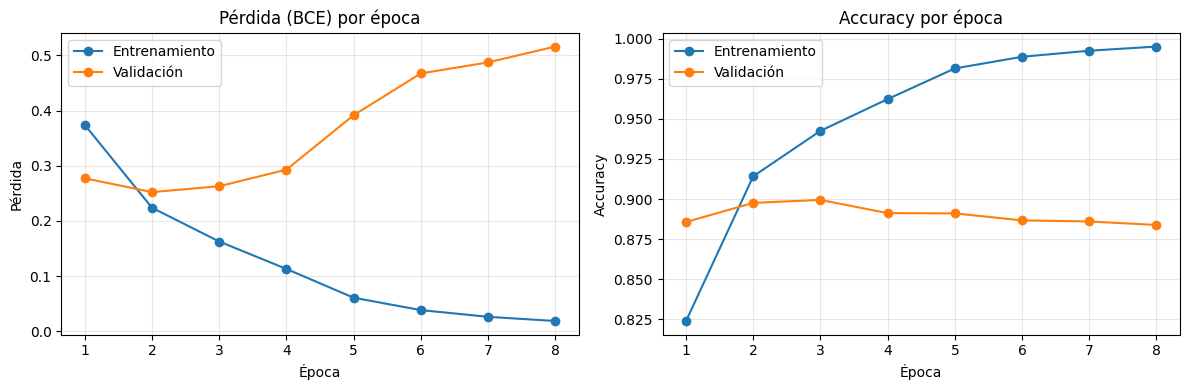

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 9. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el conjunto de prueba (15 %), que no se usó ni para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall, F1-score y la matriz de confusión.

Accuracy : 0.9040
Precisión: 0.9021
Recall   : 0.9069
F1-score : 0.9045

              precision    recall  f1-score   support

    Negativa     0.9060    0.9011    0.9035      2973
    Positiva     0.9021    0.9069    0.9045      2986

    accuracy                         0.9040      5959
   macro avg     0.9040    0.9040    0.9040      5959
weighted avg     0.9040    0.9040    0.9040      5959



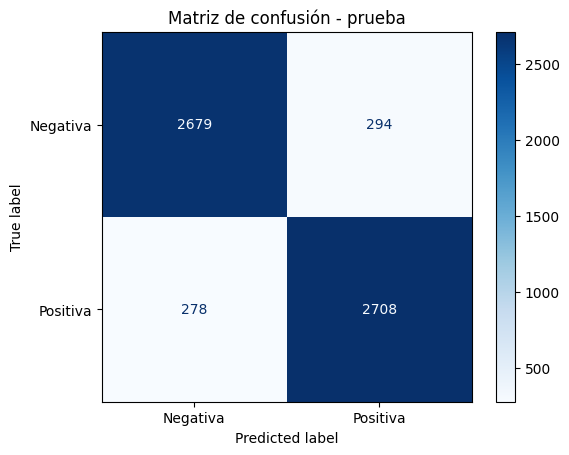

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(torch.sigmoid(modelo(xb.to(device))).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}")
print()
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba")
plt.show()

### 10. Pérdida en test, AUC y accuracy por longitud

Se calcula la pérdida en test para compararla con la de validación y el AUC de la curva ROC. También se revisa el accuracy según la cantidad de tokens de la reseña, para ver si el modelo se equivoca más en las reseñas cortas o en las de más de 400 tokens, que se recortan.

Pérdida test: 0.2502 | mejor pérdida validación: 0.2522
AUC test: 0.9648
         reseñas  accuracy
rango                     
0-50         652    0.9110
51-100      2571    0.8985
101-200     1817    0.9059
201-400      757    0.9102
>400         162    0.9136


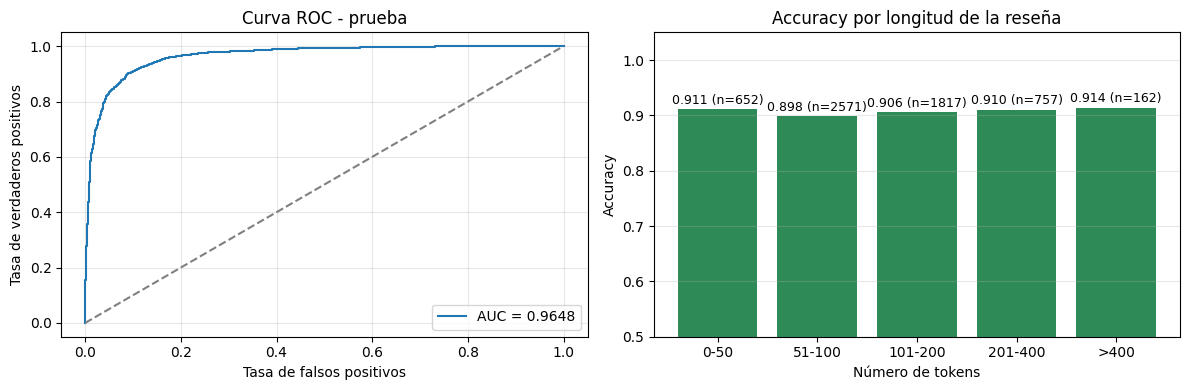

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve

modelo.eval()
logits = []
with torch.no_grad():
    for xb, _ in test_loader:
        logits.append(modelo(xb.to(device)).cpu())
logits = torch.cat(logits)

test_loss = criterio(logits, torch.tensor(y_real, dtype=torch.float32)).item()
auc = roc_auc_score(y_real, probs)
print(f"Pérdida test: {test_loss:.4f} | mejor pérdida validación: {min(historial['val_loss']):.4f}")
print(f"AUC test: {auc:.4f}")

# test_loader no tiene shuffle, entonces el orden es el mismo de test_GHI
resultados = pd.DataFrame({
    "n_tokens": test_GHI["tokens"].str.len().values,
    "real": y_real,
    "pred": y_pred,
    "prob": probs,
})
resultados["acierto"] = (resultados["real"] == resultados["pred"]).astype(int)

cortes = [0, 50, 100, 200, 400, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-400", ">400"]
resultados["rango"] = pd.cut(resultados["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud = resultados.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                               accuracy=("acierto", "mean"))
print(por_longitud.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real, probs)
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud["accuracy"], por_longitud["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 11. Ejemplos de errores

Para entender en qué se equivoca el modelo se revisan los errores en los que estaba más seguro. En los falsos positivos se toman las reseñas negativas con la probabilidad más alta de ser positivas, y en los falsos negativos las positivas con la probabilidad más baja. Se muestran 5 de cada uno.

In [17]:
resultados["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp = resultados[(resultados["real"] == 0) & (resultados["pred"] == 1)]
fn = resultados[(resultados["real"] == 1) & (resultados["pred"] == 0)]
print("Falsos positivos:", len(fp))
print("Falsos negativos:", len(fn))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 294
Falsos negativos: 278
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.998 | Tokens: 142
I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Triskel Arts Centre as part of the Cork Film Festival.  I found "Strange Fruit" to be an excellent movie. It is a bit rough around the edges, but for a low-budget movie that is to be expected! In general the acting (particularly from the main lead Kent Faulcon) is wonderful, the cinematography and direction excellent, and the script hugely entertaining and thought-provoking, with som
Probabilidad: 0.997 | Tokens: 24
Definitely not worth the rental, but if you catch it on cable, you'll be pleasantly surprised by the cameos--Iman's appearance is especially self-deprecating. It's also an opportunity to watch all the male supporting cast members from The Sopranos typecast themselves.
Probabilidad: 0.997 | Tokens: 31
I can see wh